In [1]:
import sys
sys.path.insert(0, 'C:/EnergyPlusV22-2-0/')
from pyenergyplus.api import EnergyPlusAPI
import pyenergyplus
import os
import glob
import time
import shutil
import sys
import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from threading import Thread
from multiprocessing import Process
import random
import pickle
import panel as pn
from bokeh.models import CustomJS
import tkinter as tk
from tkinter import simpledialog
import re
import openai
import os
import glob
import torch.nn as nn
import torch
os.environ['KMP_DUPLICATE_LIB_OK']='TRUE'

In [2]:
import pandas as pd
import numpy as np
import os

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import load_model

import torch.nn as nn
import torch
import torch.optim as optim
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

import random
random.seed(42)

C:\Users\liangzhang1\Anaconda3\envs\MLC_PyEMS\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [3]:
working_path = os.getcwd()

# 1. Preprocessing

In [3]:
NHTS_EV_df = pd.read_csv(working_path + '/data/NHTS_EV.csv', low_memory=False)

NHTS_non_EV_df = pd.read_csv(working_path + '/data/Non-EV dataset.csv', low_memory=False)

EV_home_ID_unique = NHTS_EV_df.HOUSEID.unique()
random.shuffle(EV_home_ID_unique)

number_of_EV_home = len(EV_home_ID_unique)

non_EV_home_ID_unique = NHTS_non_EV_df.HOUSEID.unique()
random.shuffle(non_EV_home_ID_unique)

number_of_non_EV_home = len(non_EV_home_ID_unique)

total_number_of_home = number_of_EV_home + number_of_non_EV_home

In [4]:
def start_stop_schedule(start, stop):
# start = '08:00'
# stop = '09:45'
    start_int = int(start[0:2])*60 + int(start[-2:])
    stop_int = int(stop[0:2])*60 + int(stop[-2:])
    
    schedule_list = [0]*start_int + [1]*(stop_int-start_int) + [0]*(24*60 - stop_int)
    
    return schedule_list


def process_NHTS(NHTS_EV_df, HOUSEID):

    # calculate building attributes
#     HOUSEID = 30000041

    house_attribute_list = ['HOUSEID', # Household Identifier
                            'HHFAMINC', # Household Income
                            'HHVEHCNT', # Count of household vehicles
                            'HHSIZE', # Count of household members
                            'HHSTATE', # Household State
                            'HH_RACE', # Race of household respondent
                            'HH_HISP', # Hispanic status of household respondent
                            'HH_CBSA', # Core Based Statistical Area (CBSA) FIPS code for the respondent's home address
                            'HBHUR',] # Urban / Rural indicator - Block group

    # more_attribute_list = [] # to be discussed with Alyssa and saquib

    people_attribute_list = ['PERSONID', # Person Identifier
                             'R_AGE_IMP', # Age (imputed)
                             'R_SEX_IMP', # Gender (imputed)
                             'DRIVER',] # Driver status, derived]

    building_dictionary = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID][house_attribute_list].iloc[0,:].to_dict()

    people_df = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID][people_attribute_list].set_index(['PERSONID'])


    people_dictionary = {index: row.to_dict() for index, row in people_df.iterrows()}

    building_dictionary['People'] = people_dictionary
    
    
    # calculate schedule array
    start_time_df = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID].filter(like='STRTTIME_TRIP')
    end_time_df = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID].filter(like='ENDTIME_TRIP')

    schedule_array_sum = 0
    for (index_start, row_start), (index_end, row_end) in zip(start_time_df.iterrows(), end_time_df.iterrows()):
#         print(index_start, index_end)
        schedule_array = 0
        for (start, stop) in zip(row_start.dropna(), row_end.dropna()):
#             print(start, stop)
            schedule_temp_array = np.array(start_stop_schedule(start, stop))
            schedule_array = schedule_array + schedule_temp_array
        schedule_array = -schedule_array + 1
        
        schedule_array_sum = schedule_array_sum + schedule_array
    
    schedule_array_sum = pd.DataFrame([schedule_array_sum], index = ['occupancy']).T

    return building_dictionary, schedule_array_sum

def process_NHTS_building_dictionary(NHTS_EV_df, HOUSEID):

    # calculate building attributes
#     HOUSEID = 30000041

    house_attribute_list = ['HOUSEID', # Household Identifier
                            'HHFAMINC', # Household Income
                            'HHVEHCNT', # Count of household vehicles
                            'HHSIZE', # Count of household members
                            'HHSTATE', # Household State
                            'HH_RACE', # Race of household respondent
                            'HH_HISP', # Hispanic status of household respondent
                            'HH_CBSA', # Core Based Statistical Area (CBSA) FIPS code for the respondent's home address
                            'HBHUR',] # Urban / Rural indicator - Block group

    # more_attribute_list = [] # to be discussed with Alyssa and saquib

    people_attribute_list = ['PERSONID', # Person Identifier
                             'R_AGE_IMP', # Age (imputed)
                             'R_SEX_IMP', # Gender (imputed)
                             'DRIVER',] # Driver status, derived]

    building_dictionary = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID][house_attribute_list].iloc[0,:].to_dict()
    return building_dictionary

## 1.1 EV Preprocessing

In [5]:
rerun = False

if rerun == True:
    HOUSEID_occupancy_hourly_summary = pd.DataFrame([])
    counter = 0
    for HOUSEID in EV_home_ID_unique[0:5000]:
        counter = counter + 1
        if counter%100 == 0:
            print(f"{counter}/{len(EV_home_ID_unique)}")
        try:
            HOUSEID_results = process_NHTS(NHTS_EV_df, HOUSEID)
            HOUSEID_info = HOUSEID_results[0]
            HOUSEID_occupancy = HOUSEID_results[1]
            HOUSEID_occupancy_hourly = HOUSEID_occupancy.groupby(HOUSEID_occupancy.index // 60).mean()
            HOUSEID_occupancy_hourly = pd.concat([HOUSEID_occupancy_hourly]*365, ignore_index=True)/HOUSEID_info['HHSIZE']
            HOUSEID_occupancy_hourly.columns = [str(HOUSEID)]
            HOUSEID_occupancy_hourly_summary = pd.concat([HOUSEID_occupancy_hourly_summary, HOUSEID_occupancy_hourly], axis = 1)
        except:
            print(f'fail: {HOUSEID}')

    EV_HOUSEID_occupancy_hourly_summary = HOUSEID_occupancy_hourly_summary
    EV_HOUSEID_occupancy_hourly_summary.to_csv('data/EV_HOUSEID_occupancy_hourly_summary.csv', index = None)
else:
    EV_HOUSEID_occupancy_hourly_summary = pd.read_csv('data/EV_HOUSEID_occupancy_hourly_summary.csv')
    print('Since rerun = False, read data from local file')

Since rerun = False, read data from local file


## 1.2 non-EV Preprocessing

In [6]:
rerun = False

if rerun == True:
    HOUSEID_occupancy_hourly_summary = pd.DataFrame([])
    counter = 0
    for HOUSEID in non_EV_home_ID_unique[0:5000]:
        counter = counter + 1
        if counter%100 == 0:
            print(f"{counter}/{len(non_EV_home_ID_unique)}")
        try:
            HOUSEID_results = process_NHTS(NHTS_non_EV_df, HOUSEID)
            HOUSEID_info = HOUSEID_results[0]
            HOUSEID_occupancy = HOUSEID_results[1]
            HOUSEID_occupancy_hourly = HOUSEID_occupancy.groupby(HOUSEID_occupancy.index // 60).mean()
            HOUSEID_occupancy_hourly = pd.concat([HOUSEID_occupancy_hourly]*365, ignore_index=True)/HOUSEID_info['HHSIZE']
            HOUSEID_occupancy_hourly.columns = [str(HOUSEID)]
            HOUSEID_occupancy_hourly_summary = pd.concat([HOUSEID_occupancy_hourly_summary, HOUSEID_occupancy_hourly], axis = 1)
        except:
            print(f'fail: {HOUSEID}')

    non_EV_HOUSEID_occupancy_hourly_summary = HOUSEID_occupancy_hourly_summary
    non_EV_HOUSEID_occupancy_hourly_summary.to_csv('data/non_EV_HOUSEID_occupancy_hourly_summary.csv', index = None)
else:
    non_EV_HOUSEID_occupancy_hourly_summary = pd.read_csv('data/non_EV_HOUSEID_occupancy_hourly_summary.csv')
    print('Since rerun = False, read data from local file')

Since rerun = False, read data from local file


## 1.3 EV vs non_EV

Text(0, 0.5, 'Occupancy Rate')

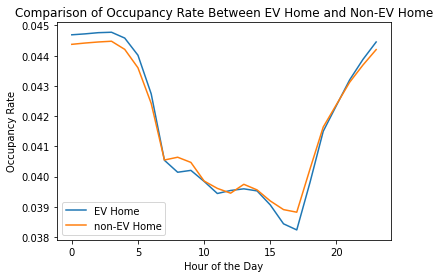

In [7]:
plt.title('Comparison of Occupancy Rate Between EV Home and Non-EV Home')
EV_ratio = EV_HOUSEID_occupancy_hourly_summary.sum(1)[0:24]/EV_HOUSEID_occupancy_hourly_summary.shape[1]
EV_ratio = EV_ratio/EV_ratio.sum()

non_EV_ratio = non_EV_HOUSEID_occupancy_hourly_summary.sum(1)[0:24]/non_EV_HOUSEID_occupancy_hourly_summary.shape[1]
non_EV_ratio = non_EV_ratio/non_EV_ratio.sum()

plt.plot(EV_ratio)
plt.plot(non_EV_ratio)
plt.legend(['EV Home','non-EV Home'])
plt.xlabel('Hour of the Day')
plt.ylabel('Occupancy Rate')

# 2. EV v.s. non-EV Analysis and Modeling

## 2.1 EV Modeling Data Preprocessing

In [8]:
rerun = False

if rerun == True:

    EV_model_data = pd.DataFrame([])

    EV_ID = EV_HOUSEID_occupancy_hourly_summary.columns.tolist()

    EV_HOUSEID_occupancy_hourly_summary_model = EV_HOUSEID_occupancy_hourly_summary[EV_ID].iloc[0:24]

    counter = 0

    for HOUSEID in EV_ID:

        counter += 1

        if counter%100 == 0:
            print(f'{counter}/{len(EV_ID)}')

        hour_of_day = EV_HOUSEID_occupancy_hourly_summary_model.index.tolist()

        HOUSEID_results = process_NHTS_building_dictionary(NHTS_EV_df, int(HOUSEID))
        HOUSEID_info = HOUSEID_results
        family_size = int(HOUSEID_info['HHSIZE'])

        df_temp = pd.DataFrame(hour_of_day, columns = ['hour_of-day'])

        df_temp['family_size'] = family_size

        df_temp['occupancy_percent'] = EV_HOUSEID_occupancy_hourly_summary_model[HOUSEID]

        EV_model_data = pd.concat([EV_model_data, df_temp], axis = 0)

    EV_model_data.to_csv('model/input_output_data_EV.csv', index = None)

else:
    EV_model_data = pd.read_csv('model/input_output_data_EV.csv')
    print('Since rerun = False, read data from local file')

Since rerun = False, read data from local file


## 2.2 EV Modeling: auto modeling using ChatGPT Interpreter

In [9]:
# Define the input and output columns
input_cols = ['hour_of-day', 'family_size']
output_cols = ['occupancy_percent']

X = EV_model_data[input_cols]
y = EV_model_data[output_cols]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert the data to PyTorch tensors
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float)

X_train_tensor.shape, y_train_tensor.shape, X_test_tensor.shape, y_test_tensor.shape

# Define the model architecture
class FeedforwardNeuralNetModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedforwardNeuralNetModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim) 
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)  

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Define the model parameters
input_dim = 2  # number of input features
hidden_dim = 30  # number of neurons in the hidden layer
output_dim = 1  # number of output features (1 since it's regression)

# Create the model
model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

# Define the loss function and the optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Train the model
num_epochs = 1000
train_losses = []

for epoch in range(num_epochs):
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Record the loss
    train_losses.append(loss.item())

    # Print loss every 10 epochs
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item()}')

# Save the model to a local directory
torch.save(model.state_dict(), working_path + '/model/EV_auto_model.pth')

Epoch 10/1000, Loss: 0.22025009989738464
Epoch 20/1000, Loss: 0.16904860734939575
Epoch 30/1000, Loss: 0.1702875792980194
Epoch 40/1000, Loss: 0.10328669100999832
Epoch 50/1000, Loss: 0.0814771056175232
Epoch 60/1000, Loss: 0.07790903747081757
Epoch 70/1000, Loss: 0.06771762669086456
Epoch 80/1000, Loss: 0.06283029168844223
Epoch 90/1000, Loss: 0.05803369730710983
Epoch 100/1000, Loss: 0.05453241989016533
Epoch 110/1000, Loss: 0.052113208919763565
Epoch 120/1000, Loss: 0.05052116885781288
Epoch 130/1000, Loss: 0.049551837146282196
Epoch 140/1000, Loss: 0.0490056611597538
Epoch 150/1000, Loss: 0.048719972372055054
Epoch 160/1000, Loss: 0.04858418181538582
Epoch 170/1000, Loss: 0.04851353168487549
Epoch 180/1000, Loss: 0.04847395047545433
Epoch 190/1000, Loss: 0.048451196402311325
Epoch 200/1000, Loss: 0.04843980446457863
Epoch 210/1000, Loss: 0.04842725768685341
Epoch 220/1000, Loss: 0.048416826874017715
Epoch 230/1000, Loss: 0.048409756273031235
Epoch 240/1000, Loss: 0.0484041832387447

In [10]:
result_list_EV = []

for i in range(24):
    # Define the model architecture
    class FeedforwardNeuralNetModel(nn.Module):
        def __init__(self, input_dim, hidden_dim, output_dim):
            super(FeedforwardNeuralNetModel, self).__init__()
            self.fc1 = nn.Linear(input_dim, hidden_dim) 
            self.relu = nn.ReLU()
            self.fc2 = nn.Linear(hidden_dim, output_dim)  

        def forward(self, x):
            out = self.fc1(x)
            out = self.relu(out)
            out = self.fc2(out)
            return out

    # Define the model parameters
    input_dim = 2  # number of input features
    hidden_dim = 30  # number of neurons in the hidden layer
    output_dim = 1  # number of output features (1 since it's regression)

    # Create the model
    model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

    # Load the model
    model.load_state_dict(torch.load(working_path + '/model/EV_auto_model.pth'))

    # Make sure the model is set to evaluation mode
    model.eval()

    # Load new data
    X_test_df = pd.DataFrame([i,4]).T.to_numpy()
    X_test_tensor = torch.from_numpy(X_test_df).float()

    # Make predictions on the new data
    with torch.no_grad():
        predictions = model(X_test_tensor)

    # Convert the predictions to a numpy array
    predictions = predictions.numpy()

    # Print the predictions
    print(predictions[0][0])
    result_list_EV.append(predictions[0][0])

0.807301
0.81024545
0.7890798
0.8025651
0.7911871
0.7730769
0.76021504
0.7503778
0.74288785
0.73539793
0.727908
0.7204178
0.7129278
0.7054107
0.6906233
0.68538946
0.69620717
0.7070248
0.7178426
0.7286602
0.73947823
0.7502957
0.7611137
0.7719312


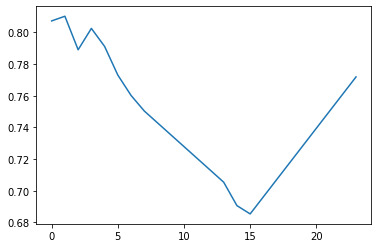

In [11]:
plt.plot(result_list_EV)

## 2.3 non-EV Model Data Preprocessing

In [12]:
rerun = False

if rerun == True:
    
    non_EV_model_data = pd.DataFrame([])

    non_EV_ID = non_EV_HOUSEID_occupancy_hourly_summary.columns.tolist()

    non_EV_HOUSEID_occupancy_hourly_summary_model = non_EV_HOUSEID_occupancy_hourly_summary[non_EV_ID].iloc[0:24]
    
    counter = 0
    for HOUSEID in non_EV_ID:
        
        counter += 1

        if counter%100 == 0:
            print(f'{counter}/{len(EV_ID)}')
        
        hour_of_day = non_EV_HOUSEID_occupancy_hourly_summary_model.index.tolist()

        HOUSEID_results = process_NHTS_building_dictionary(NHTS_non_EV_df, int(HOUSEID))
        HOUSEID_info = HOUSEID_results
        family_size = int(HOUSEID_info['HHSIZE'])

        df_temp = pd.DataFrame(hour_of_day, columns = ['hour_of-day'])

        df_temp['family_size'] = family_size

        df_temp['occupancy_percent'] = non_EV_HOUSEID_occupancy_hourly_summary_model[HOUSEID]

        non_EV_model_data = pd.concat([non_EV_model_data, df_temp], axis = 0)

    non_EV_model_data.to_csv('model/input_output_data_non_EV.csv', index = None)

else:
    non_EV_model_data = pd.read_csv('model/input_output_data_non_EV.csv')
    print('Since rerun = False, read data from local file')

Since rerun = False, read data from local file


## 2.4 non-EV Modeling: Auto ChatGPT Interpreter

In [13]:
# Define the input and output columns
input_cols = ['hour_of-day', 'family_size']
output_cols = ['occupancy_percent']

X = non_EV_model_data[input_cols]
y = non_EV_model_data[output_cols]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert the data to PyTorch tensors
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float)

X_train_tensor.shape, y_train_tensor.shape, X_test_tensor.shape, y_test_tensor.shape

# Define the model architecture
class FeedforwardNeuralNetModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedforwardNeuralNetModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim) 
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)  

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Define the model parameters
input_dim = 2  # number of input features
hidden_dim = 30  # number of neurons in the hidden layer
output_dim = 1  # number of output features (1 since it's regression)

# Create the model
model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

# Define the loss function and the optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Train the model
num_epochs = 500
train_losses = []

for epoch in range(num_epochs):
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Record the loss
    train_losses.append(loss.item())

    # Print loss every 10 epochs
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item()}')

# Save the model to a local directory
torch.save(model.state_dict(), working_path + '/model/non_EV_auto_model.pth')

Epoch 10/500, Loss: 0.149789497256279
Epoch 20/500, Loss: 0.21033351123332977
Epoch 30/500, Loss: 0.17984260618686676
Epoch 40/500, Loss: 0.12558384239673615
Epoch 50/500, Loss: 0.09040184319019318
Epoch 60/500, Loss: 0.06893794983625412
Epoch 70/500, Loss: 0.0567973330616951
Epoch 80/500, Loss: 0.05125034227967262
Epoch 90/500, Loss: 0.04997233673930168
Epoch 100/500, Loss: 0.04962575435638428
Epoch 110/500, Loss: 0.049224697053432465
Epoch 120/500, Loss: 0.049054235219955444
Epoch 130/500, Loss: 0.04894840344786644
Epoch 140/500, Loss: 0.04888886585831642
Epoch 150/500, Loss: 0.04885032773017883
Epoch 160/500, Loss: 0.04879217967391014
Epoch 170/500, Loss: 0.048725418746471405
Epoch 180/500, Loss: 0.048647183924913406
Epoch 190/500, Loss: 0.04854186251759529
Epoch 200/500, Loss: 0.04840635508298874
Epoch 210/500, Loss: 0.04825123772025108
Epoch 220/500, Loss: 0.048111479729413986
Epoch 230/500, Loss: 0.04801272973418236
Epoch 240/500, Loss: 0.04793154448270798
Epoch 250/500, Loss: 0.

In [14]:
result_list_non_EV = []

for i in range(24):
    # Define the model architecture
    class FeedforwardNeuralNetModel(nn.Module):
        def __init__(self, input_dim, hidden_dim, output_dim):
            super(FeedforwardNeuralNetModel, self).__init__()
            self.fc1 = nn.Linear(input_dim, hidden_dim) 
            self.relu = nn.ReLU()
            self.fc2 = nn.Linear(hidden_dim, output_dim)  

        def forward(self, x):
            out = self.fc1(x)
            out = self.relu(out)
            out = self.fc2(out)
            return out

    # Define the model parameters
    input_dim = 2  # number of input features
    hidden_dim = 30  # number of neurons in the hidden layer
    output_dim = 1  # number of output features (1 since it's regression)

    # Create the model
    model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

    # Load the model
    model.load_state_dict(torch.load(working_path + '/model/non_EV_auto_model.pth'))

    # Make sure the model is set to evaluation mode
    model.eval()

    # Load new data
    X_test_df = pd.DataFrame([i,4]).T.to_numpy()
    X_test_tensor = torch.from_numpy(X_test_df).float()

    # Make predictions on the new data
    with torch.no_grad():
        predictions = model(X_test_tensor)

    # Convert the predictions to a numpy array
    predictions = predictions.numpy()

    # Print the predictions
    print(predictions[0][0])
    result_list_non_EV.append(predictions[0][0])

0.74256563
0.73740315
0.7432391
0.75228417
0.75085807
0.7390652
0.7349738
0.7308827
0.72679144
0.7227
0.7186088
0.7145177
0.71042657
0.7063348
0.7022436
0.70600843
0.710776
0.71554327
0.7203109
0.7250781
0.7298459
0.73461306
0.7393805
0.7441479


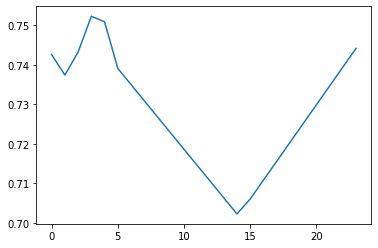

In [15]:
plt.plot(result_list_non_EV)

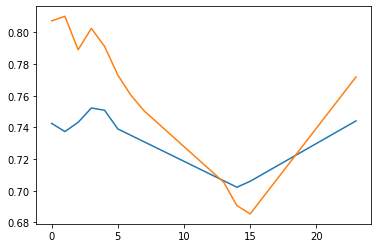

In [16]:
plt.plot(result_list_non_EV)
plt.plot(result_list_EV)

# 3. Long-Commute v.s. Short-Commute Family Analysis and Modeling

Text(0, 0.5, 'Occupancy Rate')

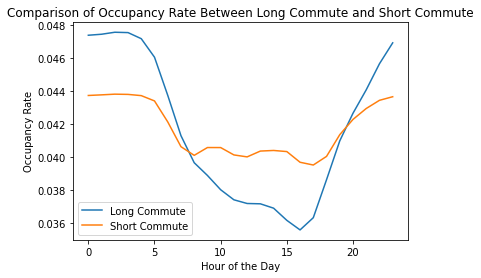

In [46]:
plt.title('Comparison of Occupancy Rate Between Long Commute and Short Commute')
long_commute_ratio = EV_HOUSEID_occupancy_hourly_summary_model_long_commute.mean(1)
long_commute_ratio = long_commute_ratio/long_commute_ratio.sum()

short_commute_ratio = EV_HOUSEID_occupancy_hourly_summary_model_short_commute.mean(1)
short_commute_ratio = short_commute_ratio/short_commute_ratio.sum()

plt.plot(savgol_filter(long_commute_ratio,5,3))
plt.plot(savgol_filter(short_commute_ratio,5,3))
plt.legend(['Long Commute','Short Commute'])
plt.xlabel('Hour of the Day')
plt.ylabel('Occupancy Rate')

0     0.960628
1     0.962625
2     0.963537
3     0.964556
4     0.956095
5     0.934719
6     0.891812
7     0.829517
8     0.806431
9     0.789380
10    0.771621
11    0.756483
12    0.754999
13    0.753455
14    0.749009
15    0.736391
16    0.718486
17    0.733608
18    0.783766
19    0.835852
20    0.862427
21    0.892673
22    0.926453
23    0.951260
dtype: float64

## 3.1 Long-Commute

In [17]:
long_commute_model_data = pd.DataFrame([])
long_commute_ID = EV_HOUSEID_occupancy_hourly_summary.sum(0).sort_values()[1000:2000].index.tolist()
EV_HOUSEID_occupancy_hourly_summary_model_long_commute = EV_HOUSEID_occupancy_hourly_summary[long_commute_ID].iloc[0:24]

for HOUSEID in EV_HOUSEID_occupancy_hourly_summary_model_long_commute:
    hour_of_day = EV_HOUSEID_occupancy_hourly_summary_model_long_commute.index.tolist()
    
    HOUSEID_results = process_NHTS(NHTS_EV_df, int(HOUSEID))
    HOUSEID_info = HOUSEID_results[0]
    family_size = int(HOUSEID_info['HHSIZE'])
    
    df_temp = pd.DataFrame(hour_of_day, columns = ['hour_of-day'])
    
    df_temp['family_size'] = family_size
    
    df_temp['occupancy_percent'] = EV_HOUSEID_occupancy_hourly_summary_model_long_commute[HOUSEID]
    
    long_commute_model_data = pd.concat([long_commute_model_data, df_temp], axis = 0)

long_commute_model_data.to_csv('model/input_output_data_long_commute.csv', index = None)

Keras

In [18]:
# # Load dataset
# X = long_commute_model_data.iloc[:,0:2]
# y = long_commute_model_data.iloc[:,2]

# # Split dataset into training and testing
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Standardize the features to have zero mean and unit variance
# # sc = StandardScaler()
# # X_train = sc.fit_transform(X_train)
# # X_test = sc.transform(X_test)

# # Define the model architecture
# model = Sequential()
# model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
# model.add(Dense(64, activation='relu'))
# model.add(Dense(64, activation='relu'))
# model.add(Dense(1))

# # Compile the model
# model.compile(optimizer='adam', loss='mean_squared_error')

# # Train the model
# model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2)

# # Evaluate the model
# mse = model.evaluate(X_test, y_test)
# print(f"Mean Squared Error on test set: {mse}")

# model.save(working_path + '/model/MLP_occupancy_long_commute.h5')

In [19]:
# model.predict(pd.DataFrame([[15, 4]]))

In [20]:
# # Load the model
# loaded_model = load_model(working_path + '/model/MLP_occupancy_long_commute.h5')

# predictions = loaded_model.predict(pd.DataFrame([[15, 4]]))[0][0]

PyTorch

In [21]:
# X_np = long_commute_model_data.iloc[:,0:2].to_numpy()
# y_np = long_commute_model_data.iloc[:,2].to_numpy()

# # Convert to PyTorch tensors
# X = torch.from_numpy(X_np).float()  # If your model expects float as input
# y = torch.from_numpy(y_np).float()  # For regression tasks you'll need float


# # Create DataLoader for your data
# dataset = TensorDataset(X, y)
# data_loader = DataLoader(dataset, batch_size=32, shuffle=True)

# # Define a simple neural network
# class Net(nn.Module):
#     def __init__(self):
#         super(Net, self).__init__()
#         self.fc1 = nn.Linear(2, 64)
#         self.fc2 = nn.Linear(64, 1)

#     def forward(self, x):
#         x = torch.relu(self.fc1(x))
#         x = self.fc2(x)
#         return x

# # Create the network and the optimizer
# model = Net()
# optimizer = optim.SGD(model.parameters(), lr=0.01)
# criterion = nn.MSELoss()

# # Train the model
# for epoch in range(50):  # 10 epochs
#     for inputs, targets in data_loader:
#         optimizer.zero_grad()
#         output = model(inputs)
#         loss = criterion(output, targets)
#         loss.backward()
#         optimizer.step()

# # Save the model
# torch.save(model.state_dict(), working_path + '/model/MLP_occupancy_long_commute.pth')



In [22]:
# # Load the model
# model = Net()  # we need to create an instance of the same model
# model.load_state_dict(torch.load(working_path + '/model/MLP_occupancy_long_commute.pth'))
# model.eval()  # Don't forget to put in eval mode before inference

# X_test_df = pd.DataFrame([0,6]).T.to_numpy()

# X_test_tensor = torch.from_numpy(X_test_df).float()

# # Use the model for inference
# with torch.no_grad():  # Inference only requires a forward pass. We don't need gradients.
#     predictions = model(X_test_tensor)[0][0].item()
# print(predictions)

auto modeling using ChatGPT Interpreter

In [23]:
# Define the input and output columns
input_cols = ['hour_of-day', 'family_size']
output_cols = ['occupancy_percent']

X = long_commute_model_data[input_cols]
y = long_commute_model_data[output_cols]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert the data to PyTorch tensors
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float)

X_train_tensor.shape, y_train_tensor.shape, X_test_tensor.shape, y_test_tensor.shape

# Define the model architecture
class FeedforwardNeuralNetModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedforwardNeuralNetModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim) 
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)  

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Define the model parameters
input_dim = 2  # number of input features
hidden_dim = 30  # number of neurons in the hidden layer
output_dim = 1  # number of output features (1 since it's regression)

# Create the model
model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

# Define the loss function and the optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Train the model
num_epochs = 1000
train_losses = []

for epoch in range(num_epochs):
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Record the loss
    train_losses.append(loss.item())

    # Print loss every 10 epochs
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item()}')

# Save the model to a local directory
torch.save(model.state_dict(), working_path + '/model/long_commute_auto_model.pth')

Epoch 10/1000, Loss: 3.0255820751190186
Epoch 20/1000, Loss: 1.1953542232513428
Epoch 30/1000, Loss: 0.48204535245895386
Epoch 40/1000, Loss: 0.14856143295764923
Epoch 50/1000, Loss: 0.10268399864435196
Epoch 60/1000, Loss: 0.0716651901602745
Epoch 70/1000, Loss: 0.05248424410820007
Epoch 80/1000, Loss: 0.04574906826019287
Epoch 90/1000, Loss: 0.04485658183693886
Epoch 100/1000, Loss: 0.044367555528879166
Epoch 110/1000, Loss: 0.043965715914964676
Epoch 120/1000, Loss: 0.04379366710782051
Epoch 130/1000, Loss: 0.043685492128133774
Epoch 140/1000, Loss: 0.04360690340399742
Epoch 150/1000, Loss: 0.04354570433497429
Epoch 160/1000, Loss: 0.04349534213542938
Epoch 170/1000, Loss: 0.04345301166176796
Epoch 180/1000, Loss: 0.04341628775000572
Epoch 190/1000, Loss: 0.04338306188583374
Epoch 200/1000, Loss: 0.04335284233093262
Epoch 210/1000, Loss: 0.04332498833537102
Epoch 220/1000, Loss: 0.043298929929733276
Epoch 230/1000, Loss: 0.04327451065182686
Epoch 240/1000, Loss: 0.043249525129795074

In [24]:
result_list_long_commute = []

for i in range(24):
    # Define the model architecture
    class FeedforwardNeuralNetModel(nn.Module):
        def __init__(self, input_dim, hidden_dim, output_dim):
            super(FeedforwardNeuralNetModel, self).__init__()
            self.fc1 = nn.Linear(input_dim, hidden_dim) 
            self.relu = nn.ReLU()
            self.fc2 = nn.Linear(hidden_dim, output_dim)  

        def forward(self, x):
            out = self.fc1(x)
            out = self.relu(out)
            out = self.fc2(out)
            return out

    # Define the model parameters
    input_dim = 2  # number of input features
    hidden_dim = 30  # number of neurons in the hidden layer
    output_dim = 1  # number of output features (1 since it's regression)

    # Create the model
    model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

    # Load the model
    model.load_state_dict(torch.load(working_path + '/model/long_commute_auto_model.pth'))

    # Make sure the model is set to evaluation mode
    model.eval()

    # Load new data
    X_test_df = pd.DataFrame([i,6]).T.to_numpy()
    X_test_tensor = torch.from_numpy(X_test_df).float()

    # Make predictions on the new data
    with torch.no_grad():
        predictions = model(X_test_tensor)

    # Convert the predictions to a numpy array
    predictions = predictions.numpy()

    # Print the predictions
    print(predictions[0][0])
    result_list_long_commute.append(predictions[0][0])

0.8245702
0.83729327
0.84037364
0.83173203
0.82850885
0.85812974
0.80236673
0.771996
0.73153496
0.71852577
0.7118658
0.7052058
0.6985457
0.69188595
0.6852263
0.678566
0.6719061
0.68092406
0.7086513
0.73637867
0.76410615
0.79183376
0.81956124
0.8472887


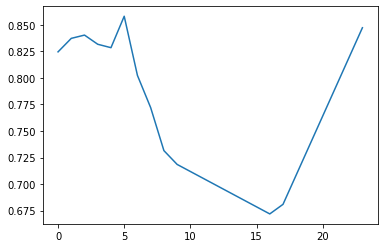

In [25]:
plt.plot(result_list_long_commute)

## 3.2 Short-Communte

In [26]:
short_commute_model_data = pd.DataFrame([])

short_commute_ID = EV_HOUSEID_occupancy_hourly_summary.sum(0).sort_values()[3000:4000].index.tolist()

EV_HOUSEID_occupancy_hourly_summary_model_short_commute = EV_HOUSEID_occupancy_hourly_summary[short_commute_ID].iloc[0:24]

for HOUSEID in EV_HOUSEID_occupancy_hourly_summary_model_short_commute:
    hour_of_day = EV_HOUSEID_occupancy_hourly_summary_model_short_commute.index.tolist()
    
    HOUSEID_results = process_NHTS(NHTS_EV_df, int(HOUSEID))
    HOUSEID_info = HOUSEID_results[0]
    family_size = int(HOUSEID_info['HHSIZE'])
    
    df_temp = pd.DataFrame(hour_of_day, columns = ['hour_of-day'])
    
    df_temp['family_size'] = family_size
    
    df_temp['occupancy_percent'] = EV_HOUSEID_occupancy_hourly_summary_model_short_commute[HOUSEID]
    
    short_commute_model_data = pd.concat([short_commute_model_data, df_temp], axis = 0)

short_commute_model_data.to_csv('model/input_output_data_short_commute.csv', index = None)

keras

In [27]:
# # Load dataset
# X = short_commute_model_data.iloc[:,0:2]
# y = short_commute_model_data.iloc[:,2]

# # Split dataset into training and testing
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Standardize the features to have zero mean and unit variance
# # sc = StandardScaler()
# # X_train = sc.fit_transform(X_train)
# # X_test = sc.transform(X_test)

# # Define the model architecture
# model = Sequential()
# model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
# model.add(Dense(64, activation='relu'))
# model.add(Dense(64, activation='relu'))
# model.add(Dense(1))

# # Compile the model
# model.compile(optimizer='adam', loss='mean_squared_error')

# # Train the model
# model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2)

# # Evaluate the model
# mse = model.evaluate(X_test, y_test)
# print(f"Mean Squared Error on test set: {mse}")

# model.save(working_path + '/model/MLP_occupancy_short_commute.h5')

PyTorch_Mannual

In [28]:
# X_np = short_commute_model_data.iloc[:,0:2].to_numpy()
# y_np = short_commute_model_data.iloc[:,2].to_numpy()

# # Convert to PyTorch tensors
# X = torch.from_numpy(X_np).float()  # If your model expects float as input
# y = torch.from_numpy(y_np).float()  # For regression tasks you'll need float


# # Create DataLoader for your data
# dataset = TensorDataset(X, y)
# data_loader = DataLoader(dataset, batch_size=32, shuffle=True)

# # Define a simple neural network
# class Net(nn.Module):
#     def __init__(self):
#         super(Net, self).__init__()
#         self.fc1 = nn.Linear(2, 64)
#         self.fc2 = nn.Linear(64, 1)

#     def forward(self, x):
#         x = torch.relu(self.fc1(x))
#         x = self.fc2(x)
#         return x

# # Create the network and the optimizer
# model = Net()
# optimizer = optim.SGD(model.parameters(), lr=0.01)
# criterion = nn.MSELoss()

# # Train the model
# for epoch in range(50):  # 10 epochs
#     for inputs, targets in data_loader:
#         optimizer.zero_grad()
#         output = model(inputs)
#         loss = criterion(output, targets)
#         loss.backward()
#         optimizer.step()

# # Save the model
# torch.save(model.state_dict(), working_path + '/model/MLP_occupancy_short_commute.pth')

In [29]:
# # Define a simple neural network
# class Net(nn.Module):
#     def __init__(self):
#         super(Net, self).__init__()
#         self.fc1 = nn.Linear(2, 64)
#         self.fc2 = nn.Linear(64, 1)

#     def forward(self, x):
#         x = torch.relu(self.fc1(x))
#         x = self.fc2(x)
#         return x

# # Load the model
# model = Net()  # we need to create an instance of the same model
# model.load_state_dict(torch.load(working_path + '/model/MLP_occupancy_short_commute.pth'))
# model.eval()  # Don't forget to put in eval mode before inference

# X_test_df = pd.DataFrame([23,6]).T.to_numpy()

# X_test_tensor = torch.from_numpy(X_test_df).float()

# # Use the model for inference
# with torch.no_grad():  # Inference only requires a forward pass. We don't need gradients.
#     predictions = model(X_test_tensor)[0][0].item()

In [30]:
# predictions

auto modeling using ChatGPT Interpreter

In [31]:
# Define the input and output columns
input_cols = ['hour_of-day', 'family_size']
output_cols = ['occupancy_percent']

X = short_commute_model_data[input_cols]
y = short_commute_model_data[output_cols]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert the data to PyTorch tensors
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float)

X_train_tensor.shape, y_train_tensor.shape, X_test_tensor.shape, y_test_tensor.shape

# Define the model architecture
class FeedforwardNeuralNetModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedforwardNeuralNetModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim) 
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)  

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Define the model parameters
input_dim = 2  # number of input features
hidden_dim = 30  # number of neurons in the hidden layer
output_dim = 1  # number of output features (1 since it's regression)

# Create the model
model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

# Define the loss function and the optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Train the model
num_epochs = 2000
train_losses = []

for epoch in range(num_epochs):
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Record the loss
    train_losses.append(loss.item())

    # Print loss every 10 epochs
    if (epoch+1) % 100 == 0:
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item()}')

# Save the model to a local directory
torch.save(model.state_dict(), working_path + '/model/short_commute_auto_model.pth')

Epoch 100/2000, Loss: 0.054091669619083405
Epoch 200/2000, Loss: 0.011023509316146374
Epoch 300/2000, Loss: 0.010789296589791775
Epoch 400/2000, Loss: 0.010682416148483753
Epoch 500/2000, Loss: 0.010527231730520725
Epoch 600/2000, Loss: 0.010432356037199497
Epoch 700/2000, Loss: 0.010381693951785564
Epoch 800/2000, Loss: 0.010351750068366528
Epoch 900/2000, Loss: 0.01033847127109766
Epoch 1000/2000, Loss: 0.010318981483578682
Epoch 1100/2000, Loss: 0.010310939513146877
Epoch 1200/2000, Loss: 0.010306431911885738
Epoch 1300/2000, Loss: 0.010290399193763733
Epoch 1400/2000, Loss: 0.010280042886734009
Epoch 1500/2000, Loss: 0.010268691927194595
Epoch 1600/2000, Loss: 0.010257948189973831
Epoch 1700/2000, Loss: 0.010238206014037132
Epoch 1800/2000, Loss: 0.01020765583962202
Epoch 1900/2000, Loss: 0.010177038609981537
Epoch 2000/2000, Loss: 0.010159376077353954


In [32]:
result_list_short_commute = []

for i in range(24):
    # Define the model architecture
    class FeedforwardNeuralNetModel(nn.Module):
        def __init__(self, input_dim, hidden_dim, output_dim):
            super(FeedforwardNeuralNetModel, self).__init__()
            self.fc1 = nn.Linear(input_dim, hidden_dim) 
            self.relu = nn.ReLU()
            self.fc2 = nn.Linear(hidden_dim, output_dim)  

        def forward(self, x):
            out = self.fc1(x)
            out = self.relu(out)
            out = self.fc2(out)
            return out

    # Define the model parameters
    input_dim = 2  # number of input features
    hidden_dim = 30  # number of neurons in the hidden layer
    output_dim = 1  # number of output features (1 since it's regression)

    # Create the model
    model = FeedforwardNeuralNetModel(input_dim, hidden_dim, output_dim)

    # Load the model
    model.load_state_dict(torch.load(working_path + '/model/short_commute_auto_model.pth'))

    # Make sure the model is set to evaluation mode
    model.eval()

    # Load new data
    X_test_df = pd.DataFrame([i,6]).T.to_numpy()
    X_test_tensor = torch.from_numpy(X_test_df).float()

    # Make predictions on the new data
    with torch.no_grad():
        predictions = model(X_test_tensor)

    # Convert the predictions to a numpy array
    predictions = predictions.numpy()

    # Print the predictions
    print(predictions[0][0])
    result_list_short_commute.append(predictions[0][0])

1.0291011
1.0216867
1.0489761
1.0501506
1.0129551
1.006501
1.0107397
0.97420824
0.962041
0.9500048
0.9392127
0.9317137
0.9242147
0.9167155
0.9092164
0.9017172
0.8942183
0.8983902
0.9194149
0.94237614
0.9653373
0.98829806
1.0112592
1.0342207


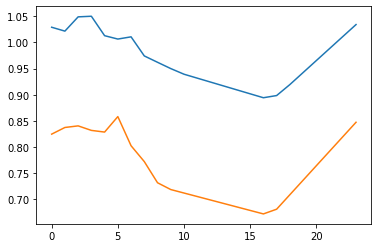

In [33]:
plt.plot(result_list_short_commute)
plt.plot(result_list_long_commute)

# 4. Static Occupancy Data Generation 

In [34]:
def start_stop_schedule(start, stop):
# start = '08:00'
# stop = '09:45'
    start_int = int(start[0:2])*60 + int(start[-2:])
    stop_int = int(stop[0:2])*60 + int(stop[-2:])
    
    schedule_list = [0]*start_int + [1]*(stop_int-start_int) + [0]*(24*60 - stop_int)
    
    return schedule_list


def process_NHTS(HOUSEID):

    # calculate building attributes
#     HOUSEID = 30000041

    NHTS_EV_df = pd.read_csv(working_path + '/data/NHTS_EV.csv', low_memory=False)

    house_attribute_list = ['HOUSEID', # Household Identifier
                            'HHFAMINC', # Household Income
                            'HHVEHCNT', # Count of household vehicles
                            'HHSIZE', # Count of household members
                            'HHSTATE', # Household State
                            'HH_RACE', # Race of household respondent
                            'HH_HISP', # Hispanic status of household respondent
                            'HH_CBSA', # Core Based Statistical Area (CBSA) FIPS code for the respondent's home address
                            'HBHUR',] # Urban / Rural indicator - Block group

    # more_attribute_list = [] # to be discussed with Alyssa and saquib

    people_attribute_list = ['PERSONID', # Person Identifier
                             'R_AGE_IMP', # Age (imputed)
                             'R_SEX_IMP', # Gender (imputed)
                             'DRIVER',] # Driver status, derived]

    building_dictionary = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID][house_attribute_list].iloc[0,:].to_dict()

    people_df = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID][people_attribute_list].set_index(['PERSONID'])


    people_dictionary = {index: row.to_dict() for index, row in people_df.iterrows()}

    building_dictionary['People'] = people_dictionary
    
    
    # calculate schedule array
    start_time_df = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID].filter(like='STRTTIME_TRIP')
    end_time_df = NHTS_EV_df.loc[NHTS_EV_df.HOUSEID == HOUSEID].filter(like='ENDTIME_TRIP')

    schedule_array_sum = 0
    for (index_start, row_start), (index_end, row_end) in zip(start_time_df.iterrows(), end_time_df.iterrows()):
#         print(index_start, index_end)
        schedule_array = 0
        for (start, stop) in zip(row_start.dropna(), row_end.dropna()):
#             print(start, stop)
            schedule_temp_array = np.array(start_stop_schedule(start, stop))
            schedule_array = schedule_array + schedule_temp_array
        schedule_array = -schedule_array + 1
        
        schedule_array_sum = schedule_array_sum + schedule_array
    
    schedule_array_sum = pd.DataFrame([schedule_array_sum], index = ['occupancy']).T

    return building_dictionary, schedule_array_sum

In [35]:
# process NHTS EV data
NHTS_EV_df = pd.read_csv(working_path + '/data/NHTS_EV.csv',low_memory=False)

HOUSEID_1 = 30000041
HOUSEID_2 = 30001124

HOUSEID_1_results = process_NHTS(HOUSEID_1)
HOUSEID_2_results = process_NHTS(HOUSEID_2)

HOUSEID_1_info = HOUSEID_1_results[0]
HOUSEID_2_info = HOUSEID_2_results[0]

# occupancy
HOUSEID_1_occupancy = HOUSEID_1_results[1]
HOUSEID_2_occupancy = HOUSEID_2_results[1]

# hourly
HOUSEID_1_occupancy_hourly = HOUSEID_1_occupancy.groupby(HOUSEID_1_occupancy.index // 60).mean()
HOUSEID_2_occupancy_hourly = HOUSEID_2_occupancy.groupby(HOUSEID_2_occupancy.index // 60).mean()

# repeat data for days
HOUSEID_1_occupancy_hourly = pd.concat([HOUSEID_1_occupancy_hourly]*365, ignore_index=True)
HOUSEID_2_occupancy_hourly = pd.concat([HOUSEID_2_occupancy_hourly]*365, ignore_index=True)

# save
HOUSEID_1_occupancy_hourly.to_csv('data/HOUSEID_1_occupancy_hourly.csv', index = None)
HOUSEID_2_occupancy_hourly.to_csv('data/HOUSEID_2_occupancy_hourly.csv', index = None)